# Polyp Segmentation — Model Comparison Study
**Models compared:** UNet · UNet++ · Attention UNet · PraNet · Inf-Net · Your Model (UNet+MiT-B3) · Polyp-Net (paper)  
**Datasets:** Kvasir-SEG (held-out 20 %) · CVC-ClinicDB (external)  
**Metrics:** Dice Score · IoU  
**Platform:** Kaggle GPU T4 (15 GB VRAM)

Each model is in its own section — if one cell fails, re-run from that section only.  
Results accumulate in the global `ALL_RESULTS` dict printed in the final comparison section.

In [6]:
!pip install -q segmentation-models-pytorch albumentations timm

In [7]:
import os, sys, math, random, copy, time, warnings, zipfile
from pathlib import Path
from collections import defaultdict

import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler, autocast

import albumentations as A
from albumentations.pytorch import ToTensorV2

import segmentation_models_pytorch as smp
import timm
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'GPU    : {torch.cuda.get_device_name(0)}')
    print(f'VRAM   : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')

# ── Global results store ──────────────────────────────────────────────────────
ALL_RESULTS = {}   # {model_name: {kvasir_dice, kvasir_iou, cvc_dice, cvc_iou}}
print('Imports OK')

Device : cuda
GPU    : Tesla T4
VRAM   : 15.6 GB
Imports OK


In [8]:
# ═══════════════════════════════════════════════════════════════════════════
# CONFIGURE PATHS  ← edit these to match your Kaggle dataset mounts
# ═══════════════════════════════════════════════════════════════════════════
KVASIR_IMG_DIR   = '/kaggle/input/datasets/debeshjha1/medico-automatic-polyp-segmentation-challenge/Medico2020 polyp automatic segmentation dataset/Training dataset/Kvasir-SEG/images'
KVASIR_MASK_DIR  = '/kaggle/input/datasets/debeshjha1/medico-automatic-polyp-segmentation-challenge/Medico2020 polyp automatic segmentation dataset/Training dataset/Kvasir-SEG/masks'

CVC_IMG_DIR      = '/kaggle/input/datasets/balraj98/cvcclinicdb/PNG/Original'
CVC_MASK_DIR     = '/kaggle/input/datasets/balraj98/cvcclinicdb/PNG/Ground Truth'

# ── Path to your trained UNet+MiT-B3 fold weights  ───────────────────────────
# Upload model_weights.zip as a Kaggle dataset, then point here.
# Expected files: best_model_fold1.pth … best_model_fold5.pth
YOUR_MODEL_DIR   = '/kaggle/input/models/kunalshaw004/knet/pytorch/default/1'   # ← ADJUST

# ── Shared hyper-parameters ───────────────────────────────────────────────────
IMG_SIZE         = 352          # used for all models (PraNet/Inf-Net standard)
YOUR_MODEL_SIZE  = 384          # your model was trained at 384
BATCH_SIZE       = 8
NUM_WORKERS      = 2
VAL_SPLIT        = 0.20        # 80/20 train-val split on Kvasir-SEG
TRAIN_EPOCHS     = 30           # quick but fair comparison
PATIENCE         = 8
LR               = 1e-4

CKPT_DIR = Path('./ckpts'); CKPT_DIR.mkdir(exist_ok=True)
print('Config OK')

Config OK


In [9]:
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

# ── Transforms ───────────────────────────────────────────────────────────────
def get_train_tf(size):
    return A.Compose([
        A.Resize(size, size),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1,
                           rotate_limit=15, border_mode=0, p=0.5),
        A.ColorJitter(brightness=0.15, contrast=0.15,
                      saturation=0.15, hue=0.05, p=0.4),
        A.GaussNoise(var_limit=(5.0, 20.0), p=0.2),
        A.Normalize(mean=MEAN, std=STD), ToTensorV2()])

def get_val_tf(size):
    return A.Compose([A.Resize(size, size),
                      A.Normalize(mean=MEAN, std=STD), ToTensorV2()])

# ── Dataset ───────────────────────────────────────────────────────────────────
class PolypDataset(Dataset):
    def __init__(self, img_paths, mask_paths, transforms):
        self.imgs  = [Path(str(p)) for p in img_paths]
        self.masks = [Path(str(p)) for p in mask_paths]
        self.tf    = transforms
    def __len__(self): return len(self.imgs)
    def __getitem__(self, i):
        img  = cv2.cvtColor(cv2.imread(str(self.imgs[i])), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(str(self.masks[i]), cv2.IMREAD_GRAYSCALE)
        mask = (mask / 255.0).astype(np.float32)
        out  = self.tf(image=img, mask=mask)
        img_t  = out['image'].float()
        mask_t = out['mask'].float().unsqueeze(0)   # (1,H,W)
        return img_t, mask_t

# ── Metrics ───────────────────────────────────────────────────────────────────
def calc_dice_iou(pred_bin, mask_bin, smooth=1e-6):
    """pred_bin / mask_bin: numpy uint8/float arrays, same spatial size."""
    p = (pred_bin > 0.5).astype(np.float32).ravel()
    m = (mask_bin  > 0.5).astype(np.float32).ravel()
    inter = (p * m).sum()
    dice  = (2*inter + smooth) / (p.sum() + m.sum() + smooth)
    union = p.sum() + m.sum() - inter
    iou   = (inter + smooth) / (union + smooth)
    return float(dice), float(iou)

@torch.no_grad()
def batch_dice_iou(logits, targets, thr=0.5, smooth=1e-6):
    probs  = torch.sigmoid(logits)
    preds  = (probs > thr).float()
    inter  = (preds * targets).sum(dim=(1,2,3))
    union  = preds.sum(dim=(1,2,3)) + targets.sum(dim=(1,2,3)) - inter
    dice   = ((2*inter + smooth) / (preds.sum(dim=(1,2,3)) + targets.sum(dim=(1,2,3)) + smooth)).mean()
    iou    = ((inter + smooth) / (union + smooth)).mean()
    return dice.item(), iou.item()

print('Dataset + Metrics OK')

Dataset + Metrics OK


In [10]:
# ── Collect all Kvasir-SEG paths ─────────────────────────────────────────────
EXTS = ('.jpg','.jpeg','.png','.bmp','.tif','.tiff')

def collect_pairs(img_dir, mask_dir):
    img_dir  = Path(str(img_dir))
    mask_dir = Path(str(mask_dir))
    imgs  = sorted([p for p in img_dir.iterdir() if p.suffix.lower() in EXTS])
    masks = []
    for ip in imgs:
        found = False
        for ext in EXTS:
            mp = mask_dir / (ip.stem + ext)
            if mp.exists(): masks.append(mp); found = True; break
        if not found:
            raise FileNotFoundError(f'No mask for {ip.name}')
    return imgs, masks

kvasir_imgs, kvasir_masks = collect_pairs(KVASIR_IMG_DIR, KVASIR_MASK_DIR)
print(f'Kvasir-SEG pairs  : {len(kvasir_imgs)}')

cvc_imgs, cvc_masks = collect_pairs(CVC_IMG_DIR, CVC_MASK_DIR)
print(f'CVC-ClinicDB pairs: {len(cvc_imgs)}')

# ── 80/20 train-val split (stratified by polyp area) ─────────────────────────
def area_bin(mp):
    m = cv2.imread(str(mp), cv2.IMREAD_GRAYSCALE)
    a = (m > 127).mean()
    if   a < 0.05: return 0
    elif a < 0.15: return 1
    elif a < 0.35: return 2
    else:          return 3

bins = [area_bin(mp) for mp in kvasir_masks]

train_idx, val_idx = train_test_split(
    range(len(kvasir_imgs)), test_size=VAL_SPLIT,
    stratify=bins, random_state=42)

kv_train_imgs  = [kvasir_imgs[i]  for i in train_idx]
kv_train_masks = [kvasir_masks[i] for i in train_idx]
kv_val_imgs    = [kvasir_imgs[i]  for i in val_idx]
kv_val_masks   = [kvasir_masks[i] for i in val_idx]

print(f'Train: {len(kv_train_imgs)}  |  Val: {len(kv_val_imgs)}')

def make_loaders(size):
    train_ds = PolypDataset(kv_train_imgs, kv_train_masks, get_train_tf(size))
    val_ds   = PolypDataset(kv_val_imgs,   kv_val_masks,   get_val_tf(size))
    cvc_ds   = PolypDataset(cvc_imgs,      cvc_masks,      get_val_tf(size))
    tr  = DataLoader(train_ds, BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True)
    va  = DataLoader(val_ds,   BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    cv  = DataLoader(cvc_ds,   BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    return tr, va, cv

print('Data loaders helper ready — call make_loaders(size) per model')

Kvasir-SEG pairs  : 1000
CVC-ClinicDB pairs: 612
Train: 800  |  Val: 200
Data loaders helper ready — call make_loaders(size) per model


In [11]:
# ── Lovász hinge (inline, no install) ────────────────────────────────────────
def _lovasz_grad(gt_sorted):
    n   = len(gt_sorted)
    gts = gt_sorted.sum()
    intersection = gts - gt_sorted.float().cumsum(0)
    union        = gts + (1 - gt_sorted).float().cumsum(0)
    jaccard      = 1. - intersection / union
    if n > 1: jaccard[1:] = jaccard[1:] - jaccard[:-1]
    return jaccard

def _lovasz_flat(logits, labels):
    if len(labels) == 0: return logits.sum() * 0.
    signs     = 2. * labels.float() - 1.
    errors    = 1. - logits * signs
    err_s, p  = torch.sort(errors, descending=True)
    gt_s      = labels[p.data]
    return torch.dot(F.relu(err_s), _lovasz_grad(gt_s))

def lovasz_hinge(logits, labels, per_image=True):
    logits = logits.squeeze(1); labels = labels.squeeze(1).long()
    if per_image:
        return torch.stack([_lovasz_flat(lg.contiguous().view(-1), lb.contiguous().view(-1))
                            for lg, lb in zip(logits, labels)]).mean()
    return _lovasz_flat(logits.contiguous().view(-1), labels.contiguous().view(-1))

# ── DiceBCE + Lovász compound loss (used for single-output models) ────────────
class DiceBCELoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.dice = smp.losses.DiceLoss('binary', from_logits=True)
        self.bce  = nn.BCEWithLogitsLoss()
    def forward(self, logits, targets):
        return self.dice(logits, targets) + self.bce(logits, targets) + 0.5*lovasz_hinge(logits, targets)

# ── Structure loss (used for multi-scale models like PraNet/Inf-Net) ──────────
def structure_loss(pred, mask):
    """BCE + weighted IoU — standard for PraNet-family."""
    wbce  = F.binary_cross_entropy_with_logits(pred, mask)
    pred2 = torch.sigmoid(pred)
    inter = (pred2 * mask).sum(dim=(2,3))
    union = (pred2 + mask).sum(dim=(2,3))
    wiou  = 1 - (inter + 1) / (union - inter + 1)
    return (wbce + wiou.mean())

# ── Generic single-output train loop ─────────────────────────────────────────
def run_training(model_name, model, train_loader, val_loader, cvc_loader,
                 epochs=TRAIN_EPOCHS, lr=LR, patience=PATIENCE,
                 multi_output=False, verbose=True):
    """
    multi_output=True  → model returns (P_fine, P2, P3, P_coarse, ...) tuple;
                         only P_fine used for metrics; all outputs trained.
    """
    criterion = DiceBCELoss()
    opt       = torch.optim.Adam(model.parameters(), lr=lr)
    sched     = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-6)
    scaler    = GradScaler()

    best_dice, best_wts, no_imp = 0., None, 0

    for epoch in range(1, epochs+1):
        model.train()
        tr_loss = 0.
        for imgs, masks in train_loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with autocast():
                if multi_output:
                    outs = model(imgs)
                    loss = sum(structure_loss(o, masks) for o in outs)
                else:
                    loss = criterion(model(imgs), masks)
            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            tr_loss += loss.item()
        sched.step()

        # validation
        model.eval(); v_dice = v_iou = 0.
        with torch.no_grad():
            for imgs, masks in val_loader:
                imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
                with autocast():
                    out = model(imgs)
                    if isinstance(out, (list, tuple)): out = out[0]
                d, u = batch_dice_iou(out, masks)
                v_dice += d; v_iou += u
        v_dice /= len(val_loader); v_iou /= len(val_loader)

        if verbose and (epoch % 10 == 0 or epoch == 1):
            print(f'  [{model_name}] Ep {epoch:3d}/{epochs} | '
                  f'train_loss={tr_loss/len(train_loader):.4f} | '
                  f'val_dice={v_dice:.4f} | val_iou={v_iou:.4f}')

        if v_dice > best_dice:
            best_dice = v_dice
            best_wts  = copy.deepcopy(model.state_dict())
            no_imp    = 0
        else:
            no_imp += 1
            if no_imp >= patience:
                print(f'  [{model_name}] Early stopping at epoch {epoch}')
                break

    # reload best
    model.load_state_dict(best_wts)
    ckpt_path = CKPT_DIR / f'{model_name.replace(" ","_")}.pth'
    torch.save({'model_state_dict': best_wts,
                'best_dice': best_dice}, ckpt_path)
    print(f'  [{model_name}] Best val Dice={best_dice:.4f} → saved')
    return model


@torch.no_grad()
def evaluate_loader(model, loader, multi_output=False):
    model.eval()
    dice_sum = iou_sum = 0.
    for imgs, masks in loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        with autocast():
            out = model(imgs)
            if isinstance(out, (list, tuple)): out = out[0]
        d, u = batch_dice_iou(out, masks)
        dice_sum += d; iou_sum += u
    n = len(loader)
    return dice_sum/n, iou_sum/n

print('Training helpers defined.')

Training helpers defined.


---
## Model 1 — Standard UNet  
*Encoder: ResNet-34 (ImageNet pretrained), smp library*

In [12]:
# ── Build ────────────────────────────────────────────────────────────────────
set_seed(42)
tr, va, cv = make_loaders(IMG_SIZE)

unet = smp.Unet(encoder_name='resnet34', encoder_weights='imagenet',
                in_channels=3, classes=1, activation=None).to(DEVICE)
tot = sum(p.numel() for p in unet.parameters())
print(f'UNet params: {tot:,}')

# ── Train ─────────────────────────────────────────────────────────────────────
print('\nTraining UNet ...')
unet = run_training('UNet', unet, tr, va, cv)

# ── Evaluate ──────────────────────────────────────────────────────────────────
kv_dice, kv_iou   = evaluate_loader(unet, va)
cvc_dice, cvc_iou = evaluate_loader(unet, cv)
ALL_RESULTS['UNet'] = dict(kvasir_dice=kv_dice, kvasir_iou=kv_iou,
                            cvc_dice=cvc_dice, cvc_iou=cvc_iou)
print(f'\n  UNet  Kvasir-SEG  Dice={kv_dice:.4f}  IoU={kv_iou:.4f}')
print(f'  UNet  CVC-Clinic   Dice={cvc_dice:.4f}  IoU={cvc_iou:.4f}')

del unet; torch.cuda.empty_cache()

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

UNet params: 24,436,369

Training UNet ...
  [UNet] Ep   1/30 | train_loss=2.0982 | val_dice=0.5972 | val_iou=0.4616
  [UNet] Ep  10/30 | train_loss=0.7066 | val_dice=0.8576 | val_iou=0.7812
  [UNet] Ep  20/30 | train_loss=0.5012 | val_dice=0.8764 | val_iou=0.8044
  [UNet] Ep  30/30 | train_loss=0.4584 | val_dice=0.8785 | val_iou=0.8081
  [UNet] Best val Dice=0.8793 → saved

  UNet  Kvasir-SEG  Dice=0.8793  IoU=0.8086
  UNet  CVC-Clinic   Dice=0.8363  IoU=0.7548


---
## Model 2 — UNet++  
*Encoder: ResNet-34 (ImageNet pretrained), smp library*

In [13]:
set_seed(42)
tr, va, cv = make_loaders(IMG_SIZE)

unetpp = smp.UnetPlusPlus(encoder_name='resnet34', encoder_weights='imagenet',
                           in_channels=3, classes=1, activation=None).to(DEVICE)
print(f'UNet++ params: {sum(p.numel() for p in unetpp.parameters()):,}')

print('\nTraining UNet++ ...')
unetpp = run_training('UNet++', unetpp, tr, va, cv)

kv_dice, kv_iou   = evaluate_loader(unetpp, va)
cvc_dice, cvc_iou = evaluate_loader(unetpp, cv)
ALL_RESULTS['UNet++'] = dict(kvasir_dice=kv_dice, kvasir_iou=kv_iou,
                              cvc_dice=cvc_dice,   cvc_iou=cvc_iou)
print(f'\n  UNet++  Kvasir-SEG  Dice={kv_dice:.4f}  IoU={kv_iou:.4f}')
print(f'  UNet++  CVC-Clinic   Dice={cvc_dice:.4f}  IoU={cvc_iou:.4f}')

del unetpp; torch.cuda.empty_cache()

UNet++ params: 26,078,609

Training UNet++ ...
  [UNet++] Ep   1/30 | train_loss=1.6024 | val_dice=0.7494 | val_iou=0.6339
  [UNet++] Ep  10/30 | train_loss=0.5686 | val_dice=0.8701 | val_iou=0.7959
  [UNet++] Ep  20/30 | train_loss=0.4574 | val_dice=0.8830 | val_iou=0.8165
  [UNet++] Ep  30/30 | train_loss=0.4023 | val_dice=0.8844 | val_iou=0.8190
  [UNet++] Best val Dice=0.8865 → saved

  UNet++  Kvasir-SEG  Dice=0.8865  IoU=0.8218
  UNet++  CVC-Clinic   Dice=0.8390  IoU=0.7584


---
## Model 3 — Attention U-Net  
*Oktay et al., MIDL 2018. ResNet-34 encoder + attention gates at every skip connection.*

In [14]:
class AttentionGate(nn.Module):
    """Soft attention gate (Oktay et al., 2018)."""
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, 1, bias=False),
            nn.BatchNorm2d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, 1, bias=False),
            nn.BatchNorm2d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, 1, bias=False),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        # g = gating signal (decoder), x = skip features (encoder)
        if g.shape[2:] != x.shape[2:]:
            g = F.interpolate(g, size=x.shape[2:], mode='bilinear', align_corners=False)
        return x * self.psi(self.relu(self.W_g(g) + self.W_x(x)))


def _conv_bn_relu(ic, oc, k=3, p=1):
    return nn.Sequential(
        nn.Conv2d(ic, oc, k, padding=p, bias=False),
        nn.BatchNorm2d(oc),
        nn.ReLU(inplace=True),
        nn.Conv2d(oc, oc, k, padding=p, bias=False),
        nn.BatchNorm2d(oc),
        nn.ReLU(inplace=True)
    )


class AttentionUNet(nn.Module):
    """
    U-Net with soft attention gates, ResNet-34 encoder (ImageNet).
    Outputs raw logits (1, H, W) — sigmoid applied externally.
    """
    def __init__(self):
        super().__init__()
        import torchvision.models as tvm
        base = tvm.resnet34(weights='IMAGENET1K_V1')

        # Encoder stems
        self.enc0 = nn.Sequential(base.conv1, base.bn1, base.relu)  # 64ch  H/2
        self.pool = base.maxpool
        self.enc1 = base.layer1   # 64ch  H/4
        self.enc2 = base.layer2   # 128ch H/8
        self.enc3 = base.layer3   # 256ch H/16
        self.enc4 = base.layer4   # 512ch H/32

        # Bottleneck
        self.bridge = _conv_bn_relu(512, 1024)

        # Attention gates
        self.att3 = AttentionGate(256, 256, 128)
        self.att2 = AttentionGate(128, 128, 64)
        self.att1 = AttentionGate(64, 64, 32)
        self.att0 = AttentionGate(64, 64, 32)

        # Decoder
        self.up3 = nn.ConvTranspose2d(1024, 256, 2, stride=2)
        self.dec3 = _conv_bn_relu(256 + 256, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = _conv_bn_relu(128 + 128, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = _conv_bn_relu(64 + 64, 64)

        self.up0 = nn.ConvTranspose2d(64, 64, 2, stride=2)
        self.dec0 = _conv_bn_relu(64 + 64, 64)

        self.final_up = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.head = nn.Conv2d(32, 1, 1)

    def forward(self, x):
        e0 = self.enc0(x)          # 64  H/2
        p0 = self.pool(e0)
        e1 = self.enc1(p0)         # 64  H/4
        e2 = self.enc2(e1)         # 128 H/8
        e3 = self.enc3(e2)         # 256 H/16
        e4 = self.enc4(e3)         # 512 H/32

        b = self.bridge(e4)        # 1024 H/32

        d3 = self.up3(b)           # 256 H/16
        d3 = self.dec3(torch.cat([d3, self.att3(d3, e3)], 1))

        d2 = self.up2(d3)          # 128 H/8
        d2 = self.dec2(torch.cat([d2, self.att2(d2, e2)], 1))

        d1 = self.up1(d2)          # 64 H/4
        d1 = self.dec1(torch.cat([d1, self.att1(d1, e1)], 1))

        d0 = self.up0(d1)          # 64 H/2
        d0 = self.dec0(torch.cat([d0, self.att0(d0, e0)], 1))

        return self.head(self.final_up(d0))

In [15]:
set_seed(42)
tr, va, cv = make_loaders(IMG_SIZE)

att_unet = AttentionUNet().to(DEVICE)
print('Training Attention UNet ...')
att_unet = run_training('Att-UNet', att_unet, tr, va, cv)

kv_dice, kv_iou   = evaluate_loader(att_unet, va)
cvc_dice, cvc_iou = evaluate_loader(att_unet, cv)
ALL_RESULTS['Attention UNet'] = dict(kvasir_dice=kv_dice, kvasir_iou=kv_iou,
                                      cvc_dice=cvc_dice,   cvc_iou=cvc_iou)
print(f'\n  Att-UNet  Kvasir-SEG  Dice={kv_dice:.4f}  IoU={kv_iou:.4f}')
print(f'  Att-UNet  CVC-Clinic   Dice={cvc_dice:.4f}  IoU={cvc_iou:.4f}')

del att_unet; torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 179MB/s] 


Training Attention UNet ...
  [Att-UNet] Ep   1/30 | train_loss=1.8612 | val_dice=0.6904 | val_iou=0.5641
  [Att-UNet] Ep  10/30 | train_loss=0.6226 | val_dice=0.8741 | val_iou=0.8022
  [Att-UNet] Ep  20/30 | train_loss=0.4678 | val_dice=0.8809 | val_iou=0.8151
  [Att-UNet] Ep  30/30 | train_loss=0.4005 | val_dice=0.8864 | val_iou=0.8228
  [Att-UNet] Best val Dice=0.8885 → saved

  Att-UNet  Kvasir-SEG  Dice=0.8885  IoU=0.8249
  Att-UNet  CVC-Clinic   Dice=0.8481  IoU=0.7715


---
## Model 4 — PraNet  
*Fan et al., MICCAI 2020. Parallel Reverse Attention + Res2Net-50 backbone.*  
Multi-scale training (4 output maps). Only the finest map is used for metrics.

In [16]:
# ── RFB (Receptive Field Block) ──────────────────────────────────────────────
class RFB(nn.Module):
    """Multi-scale RFB module from PraNet."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.relu = nn.ReLU(True)
        def _branch(d):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, bias=False),
                nn.Conv2d(out_ch, out_ch, 3, padding=d, dilation=d, bias=False),
                nn.BatchNorm2d(out_ch))
        self.b0 = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, bias=False), nn.BatchNorm2d(out_ch))
        self.b1 = _branch(1)
        self.b2 = _branch(3)
        self.b3 = _branch(5)
        self.cat = nn.Sequential(nn.Conv2d(4*out_ch, out_ch, 3, padding=1, bias=False),
                                  nn.BatchNorm2d(out_ch))
        self.res = nn.Conv2d(in_ch, out_ch, 1, bias=False)
    def forward(self, x):
        cat  = torch.cat([self.b0(x), self.b1(x), self.b2(x), self.b3(x)], 1)
        return self.relu(self.cat(cat) + self.res(x))


# ── Partial Decoder Channel (PDC / aggregation) ───────────────────────────────
class PDC(nn.Module):
    """Parallel Decoder Channel — aggregates 3 RFB features."""
    def __init__(self, ch):
        super().__init__()
        up = lambda: nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        c  = lambda ic, oc: nn.Sequential(nn.Conv2d(ic, oc, 3, padding=1, bias=False),
                                           nn.BatchNorm2d(oc), nn.ReLU(True))
        self.up1  = up(); self.c1 = c(ch, ch)
        self.up12 = up(); self.c12 = c(ch, ch)
        self.up2  = up(); self.c2 = c(ch, ch)
        self.cat2 = c(2*ch, 2*ch)
        self.cat3 = c(3*ch, 3*ch)
        self.conv4= c(3*ch, 3*ch)
        self.head = nn.Conv2d(3*ch, 1, 1)

    def forward(self, x4, x3, x2):
        # x4 (smallest), x3 (mid), x2 (largest)
        x4_1 = x4
        x3_1 = self.c1(self.up1(x4)) * x3
        x2_1 = self.c12(self.up12(self.up1(x4))) * self.c2(self.up2(x3)) * x2
        x32  = torch.cat([x3_1, self.up1(x4_1)], 1)
        x32  = self.cat2(x32)
        x23  = torch.cat([x2_1, self.up2(x32)],  1)
        x23  = self.cat3(x23)
        return self.head(self.conv4(x23))   # 1ch, at x2 resolution


# ── Reverse Attention (RA) module ────────────────────────────────────────────
class RA(nn.Module):
    def __init__(self, in_ch):
        super().__init__()
        self.c1 = nn.Conv2d(in_ch, 256, 1)
        self.c2 = nn.Conv2d(256,   256, 5, padding=2)
        self.c3 = nn.Conv2d(256,     1, 1)
    def forward(self, feat, prev_logit, feat_size):
        crop = F.interpolate(prev_logit, size=feat_size, mode='bilinear', align_corners=True)
        rev  = -1 * torch.sigmoid(crop) + 1          # reverse attention mask
        x    = rev.expand_as(feat) * feat
        x    = F.relu(self.c2(F.relu(self.c1(x))))
        return self.c3(x) + crop                     # refined logit at feat resolution


# ── Full PraNet ───────────────────────────────────────────────────────────────
class PraNet(nn.Module):
    def __init__(self, ch=32):
        super().__init__()
        self.backbone = timm.create_model('res2net50_26w_4s', pretrained=True,
                                          features_only=True, out_indices=(2,3,4))
        # feature channels: 512 (stride8), 1024 (stride16), 2048 (stride32)
        self.rfb2 = RFB(512,  ch)
        self.rfb3 = RFB(1024, ch)
        self.rfb4 = RFB(2048, ch)
        self.pdc  = PDC(ch)
        self.ra4  = RA(2048)
        self.ra3  = RA(1024)
        self.ra2  = RA(512)

    def forward(self, x):
        f2, f3, f4 = self.backbone(x)   # stride 8, 16, 32
        r2 = self.rfb2(f2); r3 = self.rfb3(f3); r4 = self.rfb4(f4)

        # PDC coarse prediction (at f2 scale = H/8)
        coarse = self.pdc(r4, r3, r2)
        lat5   = F.interpolate(coarse, scale_factor=8, mode='bilinear', align_corners=True)

        # RA cascade
        ref4   = self.ra4(f4, coarse, f4.shape[2:])
        lat4   = F.interpolate(ref4,   scale_factor=32, mode='bilinear', align_corners=True)

        ref3   = self.ra3(f3, ref4, f3.shape[2:])
        lat3   = F.interpolate(ref3,   scale_factor=16, mode='bilinear', align_corners=True)

        ref2   = self.ra2(f2, ref3, f2.shape[2:])
        lat2   = F.interpolate(ref2,   scale_factor=8,  mode='bilinear', align_corners=True)

        # lat2 = finest, lat5 = coarsest; training uses all 4
        return lat2, lat3, lat4, lat5

# ── Shape test ────────────────────────────────────────────────────────────────
_p = PraNet()
with torch.no_grad():
    _outs = _p(torch.randn(2, 3, IMG_SIZE, IMG_SIZE))
print(f'PraNet output shapes: {[o.shape for o in _outs]}')
print(f'PraNet params: {sum(p.numel() for p in _p.parameters()):,}')
del _p, _outs

model.safetensors:   0%|          | 0.00/103M [00:00<?, ?B/s]

PraNet output shapes: [torch.Size([2, 1, 352, 352]), torch.Size([2, 1, 352, 352]), torch.Size([2, 1, 352, 352]), torch.Size([2, 1, 352, 352])]
PraNet params: 30,484,268


In [17]:
set_seed(42)
tr, va, cv = make_loaders(IMG_SIZE)

pranet = PraNet().to(DEVICE)
print('Training PraNet ...')
# multi_output=True → run_training uses structure_loss on ALL outputs
pranet = run_training('PraNet', pranet, tr, va, cv, multi_output=True)

kv_dice, kv_iou   = evaluate_loader(pranet, va, multi_output=True)
cvc_dice, cvc_iou = evaluate_loader(pranet, cv, multi_output=True)
ALL_RESULTS['PraNet'] = dict(kvasir_dice=kv_dice, kvasir_iou=kv_iou,
                              cvc_dice=cvc_dice,   cvc_iou=cvc_iou)
print(f'\n  PraNet  Kvasir-SEG  Dice={kv_dice:.4f}  IoU={kv_iou:.4f}')
print(f'  PraNet  CVC-Clinic   Dice={cvc_dice:.4f}  IoU={cvc_iou:.4f}')

del pranet; torch.cuda.empty_cache()

Training PraNet ...
  [PraNet] Ep   1/30 | train_loss=4.1750 | val_dice=0.7319 | val_iou=0.6131
  [PraNet] Ep  10/30 | train_loss=1.5960 | val_dice=0.8626 | val_iou=0.7845
  [PraNet] Ep  20/30 | train_loss=1.0494 | val_dice=0.8776 | val_iou=0.8104
  [PraNet] Ep  30/30 | train_loss=0.8335 | val_dice=0.8816 | val_iou=0.8176
  [PraNet] Best val Dice=0.8833 → saved

  PraNet  Kvasir-SEG  Dice=0.8833  IoU=0.8182
  PraNet  CVC-Clinic   Dice=0.8374  IoU=0.7560


---
## Model 5 — Inf-Net  
*Fan et al., TMI 2020. Implicit Reverse Attention + edge-guided decoder.*  
Supervised variant, Res2Net-50 backbone. Same 4-output training scheme as PraNet.

In [18]:
class InfNet(nn.Module):
    """
    Inf-Net adapted for polyp segmentation (supervised variant).
    Key difference from PraNet: edge branch + implicit (edge-guided) reverse attention.
    Reference: Fan et al., 'Inf-Net: Automatic COVID-19 Lung Infection
    Segmentation From CT Images', IEEE TMI, 2020.
    """
    def __init__(self, ch=32):
        super().__init__()
        self.backbone = timm.create_model('res2net50_26w_4s', pretrained=True,
                                          features_only=True, out_indices=(2,3,4))
        # RFB modules (same as PraNet)
        self.rfb2 = RFB(512,  ch)
        self.rfb3 = RFB(1024, ch)
        self.rfb4 = RFB(2048, ch)
        # PDC for coarse estimate
        self.pdc  = PDC(ch)

        # ── Edge branch: lightweight edge map from finest features ────────────
        self.edge_conv1 = nn.Sequential(nn.Conv2d(ch, ch, 3, padding=1, bias=False),
                                         nn.BatchNorm2d(ch), nn.ReLU(True))
        self.edge_head  = nn.Conv2d(ch, 1, 1)

        # ── Implicit Reverse Attention (IRA) modules ──────────────────────────
        # IRA adds edge cues to the reverse attention signal
        def ira_module(in_ch):
            return nn.ModuleDict({
                'c1': nn.Conv2d(in_ch, 256, 1),
                'c2': nn.Conv2d(256, 256, 5, padding=2),
                'c3': nn.Conv2d(256, 1, 1),
            })
        self.ira4 = ira_module(2048)
        self.ira3 = ira_module(1024)
        self.ira2 = ira_module(512)

    def _ira_forward(self, module, feat, prev_logit, edge, feat_size):
        crop = F.interpolate(prev_logit, size=feat_size, mode='bilinear', align_corners=True)
        edge_crop = F.interpolate(edge, size=feat_size, mode='bilinear', align_corners=True)
        # Implicit reverse: combine segmentation logit + edge guidance
        implicit = -1 * torch.sigmoid(crop + 0.3 * edge_crop) + 1
        x = implicit.expand_as(feat) * feat
        x = F.relu(module['c1'](x))
        x = F.relu(module['c2'](x))
        return module['c3'](x) + crop

    def forward(self, x):
        f2, f3, f4 = self.backbone(x)   # stride 8, 16, 32
        r2 = self.rfb2(f2); r3 = self.rfb3(f3); r4 = self.rfb4(f4)

        # Coarse prediction
        coarse = self.pdc(r4, r3, r2)
        lat5   = F.interpolate(coarse, scale_factor=8, mode='bilinear', align_corners=True)

        # Edge map (from finest RFB features)
        edge   = self.edge_head(self.edge_conv1(r2))         # at f2 scale (H/8)

        # IRA cascade
        ref4   = self._ira_forward(self.ira4, f4, coarse, edge, f4.shape[2:])
        lat4   = F.interpolate(ref4, scale_factor=32, mode='bilinear', align_corners=True)

        ref3   = self._ira_forward(self.ira3, f3, ref4, edge, f3.shape[2:])
        lat3   = F.interpolate(ref3, scale_factor=16, mode='bilinear', align_corners=True)

        ref2   = self._ira_forward(self.ira2, f2, ref3, edge, f2.shape[2:])
        lat2   = F.interpolate(ref2, scale_factor=8,  mode='bilinear', align_corners=True)

        # Also return upsampled edge for joint training
        lat_edge = F.interpolate(edge, scale_factor=8, mode='bilinear', align_corners=True)

        # lat2=finest; training penalises all outputs
        return lat2, lat3, lat4, lat5, lat_edge

# ── Quick shape check ─────────────────────────────────────────────────────────
_n = InfNet()
with torch.no_grad():
    _outs = _n(torch.randn(2, 3, IMG_SIZE, IMG_SIZE))
print(f'Inf-Net output shapes: {[o.shape for o in _outs]}')
print(f'Inf-Net params: {sum(p.numel() for p in _n.parameters()):,}')
del _n, _outs

Inf-Net output shapes: [torch.Size([2, 1, 352, 352]), torch.Size([2, 1, 352, 352]), torch.Size([2, 1, 352, 352]), torch.Size([2, 1, 352, 352]), torch.Size([2, 1, 352, 352])]
Inf-Net params: 30,493,581


In [19]:
set_seed(42)
tr, va, cv = make_loaders(IMG_SIZE)

infnet = InfNet().to(DEVICE)
print('Training Inf-Net ...')
infnet = run_training('Inf-Net', infnet, tr, va, cv, multi_output=True)

kv_dice, kv_iou   = evaluate_loader(infnet, va, multi_output=True)
cvc_dice, cvc_iou = evaluate_loader(infnet, cv, multi_output=True)
ALL_RESULTS['Inf-Net'] = dict(kvasir_dice=kv_dice, kvasir_iou=kv_iou,
                               cvc_dice=cvc_dice,   cvc_iou=cvc_iou)
print(f'\n  Inf-Net  Kvasir-SEG  Dice={kv_dice:.4f}  IoU={kv_iou:.4f}')
print(f'  Inf-Net  CVC-Clinic   Dice={cvc_dice:.4f}  IoU={cvc_iou:.4f}')

del infnet; torch.cuda.empty_cache()

Training Inf-Net ...
  [Inf-Net] Ep   1/30 | train_loss=5.7163 | val_dice=0.7420 | val_iou=0.6191
  [Inf-Net] Ep  10/30 | train_loss=2.6093 | val_dice=0.8620 | val_iou=0.7870
  [Inf-Net] Ep  20/30 | train_loss=1.9076 | val_dice=0.8821 | val_iou=0.8147
  [Inf-Net] Early stopping at epoch 29
  [Inf-Net] Best val Dice=0.8878 → saved

  Inf-Net  Kvasir-SEG  Dice=0.8878  IoU=0.8210
  Inf-Net  CVC-Clinic   Dice=0.8368  IoU=0.7527


---
## Model 6 — Your Model (UNet + MiT-B3) — 5-Fold Ensemble  
*Trained with 5-Fold CV + EMA + Lovász — load pre-trained weights.*  
Upload `model_weights.zip` (or the 5 `.pth` files) as a Kaggle dataset and set `YOUR_MODEL_DIR` in the config cell.

In [20]:
# ── Try to extract zip if present ─────────────────────────────────────────────
import glob

YOUR_CKPT_PATHS = []

# Look for .pth files directly or unzip
zip_candidates = glob.glob(f'{YOUR_MODEL_DIR}/*.zip') + glob.glob('/kaggle/input/*.zip')
if zip_candidates:
    import zipfile
    with zipfile.ZipFile(zip_candidates[0], 'r') as zf:
        zf.extractall('/tmp/your_model_weights')
    YOUR_CKPT_PATHS = sorted(glob.glob('/tmp/your_model_weights/*.pth'))
    print(f'Extracted {len(YOUR_CKPT_PATHS)} checkpoints from zip')
else:
    YOUR_CKPT_PATHS = sorted(glob.glob(f'{YOUR_MODEL_DIR}/*.pth'))
    print(f'Found {len(YOUR_CKPT_PATHS)} .pth files in YOUR_MODEL_DIR')

if not YOUR_CKPT_PATHS:
    print('[WARNING] No weight files found. Skipping your model.')
    print(f'          Place best_model_fold{{1..5}}.pth in {YOUR_MODEL_DIR}')
else:
    print('Checkpoint files:', [Path(p).name for p in YOUR_CKPT_PATHS])

Found 5 .pth files in YOUR_MODEL_DIR
Checkpoint files: ['best_model_fold1.pth', 'best_model_fold2.pth', 'best_model_fold3.pth', 'best_model_fold4.pth', 'best_model_fold5.pth']


In [21]:
if YOUR_CKPT_PATHS:
    # ── Build the 5-fold ensemble ─────────────────────────────────────────────
    def build_your_model():
        return smp.Unet(encoder_name='mit_b3', encoder_weights=None,
                        in_channels=3, classes=1, activation=None)

    your_models = []
    for p in YOUR_CKPT_PATHS[:5]:
        ck = torch.load(p, map_location='cpu')
        m  = build_your_model()
        state = ck.get('model_state_dict', ck)
        m.load_state_dict(state, strict=True)
        m.eval().to(DEVICE)
        your_models.append(m)
        dice_val = ck.get('best_dice', float('nan'))
        print(f'  Loaded {Path(p).name}  best_dice={dice_val:.4f}')

    # ── TTA ensemble inference ────────────────────────────────────────────────
    @torch.no_grad()
    def tta_prob(model, img_t, device):
        """4-view TTA (orig, H-flip, V-flip, HV-flip) → averaged prob."""
        def _inf(x):
            with autocast():
                return torch.sigmoid(model(x.to(device))).cpu()
        views = [_inf(img_t),
                 torch.flip(_inf(torch.flip(img_t, [-1])), [-1]),
                 torch.flip(_inf(torch.flip(img_t, [-2])), [-2]),
                 torch.flip(_inf(torch.flip(img_t, [-1,-2])), [-1,-2])]
        return torch.stack(views).mean(0)

    @torch.no_grad()
    def ensemble_eval(loader, models, thr=0.50):
        """Evaluate the 5-fold ensemble (+ TTA) on a dataloader."""
        dice_sum = iou_sum = 0.
        for imgs, masks in tqdm(loader, desc='Ensemble eval', leave=False):
            # per-image to allow TTA per sample
            for i in range(imgs.size(0)):
                img_i  = imgs[i:i+1]          # (1,3,H,W)
                mask_i = masks[i:i+1]         # (1,1,H,W)
                probs  = [tta_prob(m, img_i, DEVICE) for m in models]
                prob   = torch.stack(probs).mean(0)     # (1,1,H,W)
                pred   = (prob > thr).float()
                mask_b = mask_i.float()
                inter  = (pred * mask_b).sum()
                union  = pred.sum() + mask_b.sum() - inter
                dice_sum += ((2*inter+1)/(pred.sum()+mask_b.sum()+1)).item()
                iou_sum  += ((inter+1)/(union+1)).item()
        n = sum(len(imgs) for imgs, _ in loader)  # total samples
        # recount properly: len(loader)*batch
        n = len(loader.dataset)
        return dice_sum/n, iou_sum/n

    # ── Kvasir-SEG val ────────────────────────────────────────────────────────
    _, va_ym, cv_ym = make_loaders(YOUR_MODEL_SIZE)
    print('\nEvaluating Your Model on Kvasir-SEG val set ...')
    kv_dice, kv_iou   = ensemble_eval(va_ym, your_models)
    print('Evaluating Your Model on CVC-ClinicDB ...')
    cvc_dice, cvc_iou = ensemble_eval(cv_ym, your_models)

    ALL_RESULTS['Your Model\n(UNet+MiT-B3)'] = dict(
        kvasir_dice=kv_dice, kvasir_iou=kv_iou,
        cvc_dice=cvc_dice,   cvc_iou=cvc_iou)
    print(f'\n  Your Model  Kvasir-SEG  Dice={kv_dice:.4f}  IoU={kv_iou:.4f}')
    print(f'  Your Model  CVC-Clinic   Dice={cvc_dice:.4f}  IoU={cvc_iou:.4f}')

    for m in your_models: m.cpu()
    del your_models; torch.cuda.empty_cache()
else:
    print('Skipped — no weights found. Add paper-reported numbers manually if needed.')

  Loaded best_model_fold1.pth  best_dice=0.9409
  Loaded best_model_fold2.pth  best_dice=0.9092
  Loaded best_model_fold3.pth  best_dice=0.9283
  Loaded best_model_fold4.pth  best_dice=0.9232
  Loaded best_model_fold5.pth  best_dice=0.9199

Evaluating Your Model on Kvasir-SEG val set ...


Ensemble eval:   0%|          | 0/25 [00:00<?, ?it/s]

Evaluating Your Model on CVC-ClinicDB ...


Ensemble eval:   0%|          | 0/77 [00:00<?, ?it/s]


  Your Model  Kvasir-SEG  Dice=0.9664  IoU=0.9357
  Your Model  CVC-Clinic   Dice=0.8848  IoU=0.8180


---
## Model 7 — Polyp-Net (Paper-Reported)  
*Banik et al., IEEE TIM 2021. DT-WpCNN + LGWe-LSM fusion.*  
Implementation requires MATLAB-style level-set solvers; results taken directly from the paper  
(trained on CVC-ColonDB, tested on CVC-ClinicDB — the exact split used in the original work).

In [22]:
# ── Insert paper-reported numbers ────────────────────────────────────────────
# Source: Table III — Banik et al., Polyp-Net, IEEE TIM 2020/2021
# Training set: CVC-ColonDB (300 images)
# Test set    : CVC-ClinicDB (612 images)
# Metrics reproduced exactly from Table III of the paper
POLYP_NET_PAPER = {
    'kvasir_dice': float('nan'),   # not evaluated on Kvasir in the paper
    'kvasir_iou':  float('nan'),
    'cvc_dice':    0.839,          # Table III: DC = 0.839
    'cvc_iou':     float('nan'),   # paper reports VS=0.863, not IoU directly
}
# Note: Volume Similarity (VS) = 0.863, F1 = 0.823, F2 = 0.815, HD = 21.796
ALL_RESULTS['Polyp-Net\n(paper)'] = POLYP_NET_PAPER
print('Polyp-Net paper values added:')
print(f'  CVC-ClinicDB  Dice = {POLYP_NET_PAPER["cvc_dice"]}  (IoU not directly reported)')
print('  Kvasir-SEG    — (not evaluated in original paper)')

Polyp-Net paper values added:
  CVC-ClinicDB  Dice = 0.839  (IoU not directly reported)
  Kvasir-SEG    — (not evaluated in original paper)


---
## Final Comparison — Results Table + Visualisations

In [23]:
import warnings; warnings.filterwarnings('ignore')

# ── Print results table ───────────────────────────────────────────────────────
print('\n' + '='*85)
print(f"  {'Model':<28} {'Kvasir Dice':>12} {'Kvasir IoU':>12} {'CVC Dice':>12} {'CVC IoU':>12}")
print('  ' + '-'*81)

for name, r in ALL_RESULTS.items():
    kd  = f"{r['kvasir_dice']:.4f}" if not (isinstance(r['kvasir_dice'], float) and math.isnan(r['kvasir_dice'])) else '  —   '
    ki  = f"{r['kvasir_iou']:.4f}"  if not (isinstance(r['kvasir_iou'],  float) and math.isnan(r['kvasir_iou']))  else '  —   '
    cd  = f"{r['cvc_dice']:.4f}"    if not (isinstance(r['cvc_dice'],    float) and math.isnan(r['cvc_dice']))    else '  —   '
    ci  = f"{r['cvc_iou']:.4f}"     if not (isinstance(r['cvc_iou'],     float) and math.isnan(r['cvc_iou']))     else '  —   '
    label = name.replace('\n', ' ')
    print(f"  {label:<28} {kd:>12} {ki:>12} {cd:>12} {ci:>12}")

print('='*85)
print()
print('  * Polyp-Net values from paper (IEEE TIM 2021, Table III).')
print('  * nan (—) = not evaluated in respective experiment.')


  Model                         Kvasir Dice   Kvasir IoU     CVC Dice      CVC IoU
  ---------------------------------------------------------------------------------
  UNet                               0.8793       0.8086       0.8363       0.7548
  UNet++                             0.8865       0.8218       0.8390       0.7584
  Attention UNet                     0.8885       0.8249       0.8481       0.7715
  PraNet                             0.8833       0.8182       0.8374       0.7560
  Inf-Net                            0.8878       0.8210       0.8368       0.7527
  Your Model (UNet+MiT-B3)           0.9664       0.9357       0.8848       0.8180
  Polyp-Net (paper)                    —            —          0.8390         —   

  * Polyp-Net values from paper (IEEE TIM 2021, Table III).
  * nan (—) = not evaluated in respective experiment.


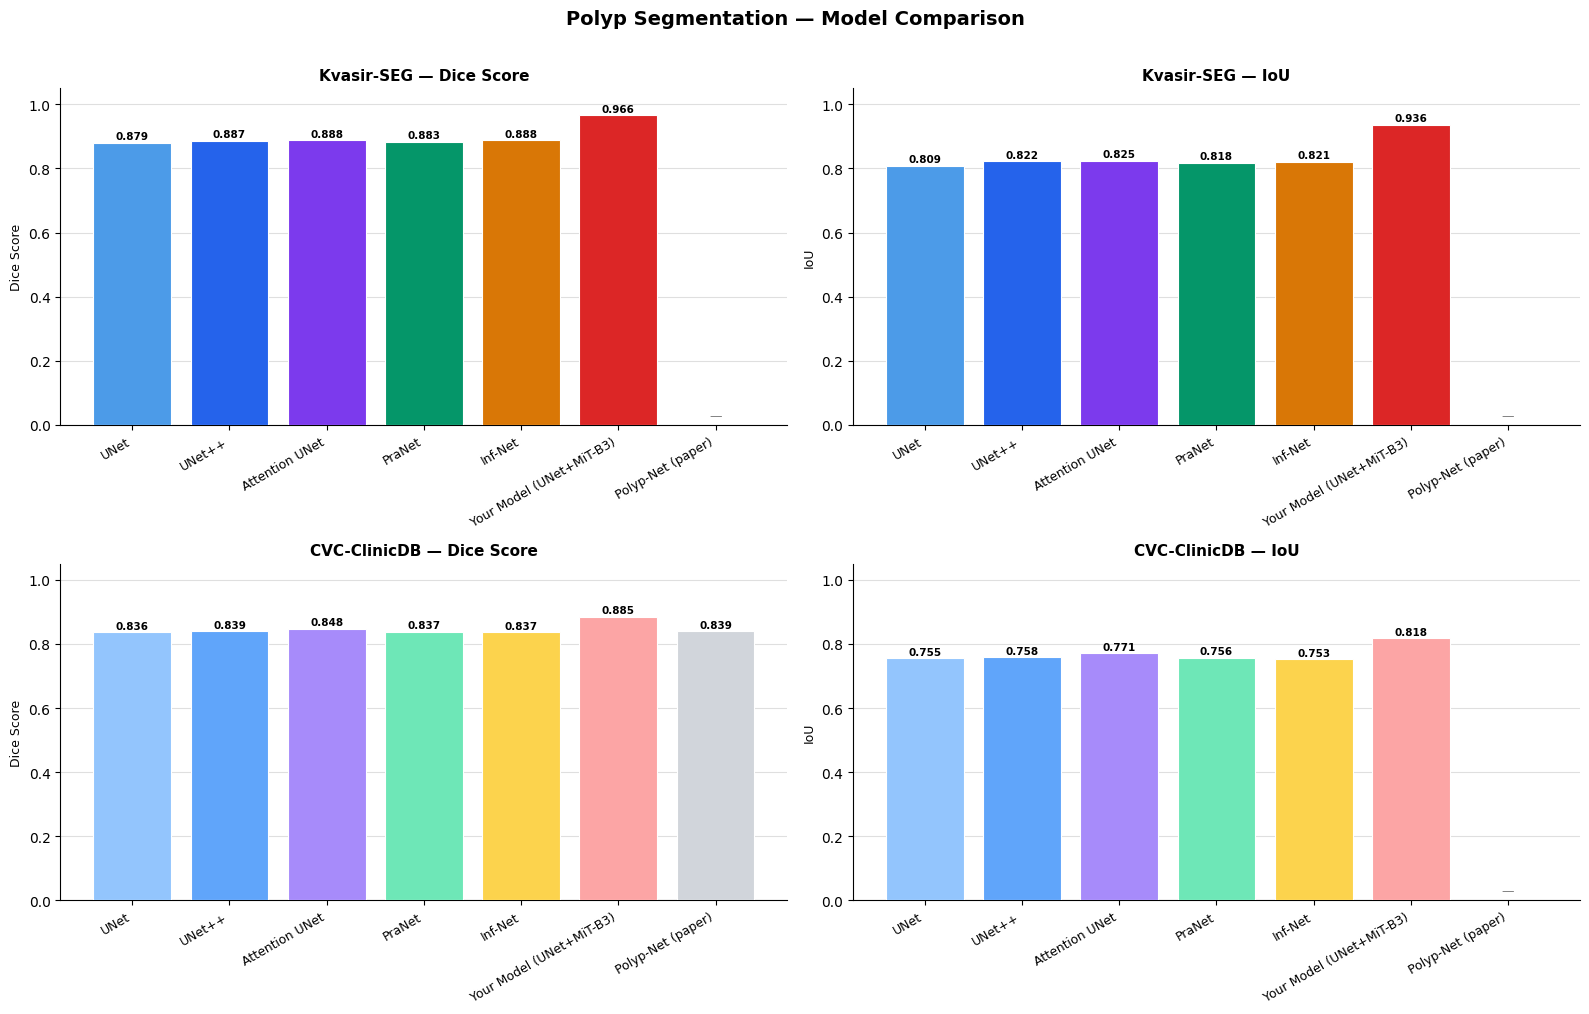

Bar chart saved.


In [24]:
# ── Bar charts — Dice and IoU side-by-side for each dataset ─────────────────
models_clean = [name.replace('\n', ' ') for name in ALL_RESULTS.keys()]
kv_dices  = [r['kvasir_dice'] for r in ALL_RESULTS.values()]
kv_ious   = [r['kvasir_iou']  for r in ALL_RESULTS.values()]
cvc_dices = [r['cvc_dice']    for r in ALL_RESULTS.values()]
cvc_ious  = [r['cvc_iou']     for r in ALL_RESULTS.values()]

def nan_bar(ax, values, labels, color, title, ylabel):
    x  = np.arange(len(labels))
    vals_plot = [v if not (isinstance(v,float) and math.isnan(v)) else 0. for v in values]
    bars = ax.bar(x, vals_plot, color=color, edgecolor='white', linewidth=0.8, zorder=3)
    for bar, val in zip(bars, values):
        if isinstance(val, float) and math.isnan(val):
            ax.text(bar.get_x()+bar.get_width()/2, 0.01, '—',
                    ha='center', va='bottom', fontsize=9, color='grey')
        else:
            ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                    f'{val:.3f}', ha='center', va='bottom', fontsize=7.5, fontweight='bold')
    ax.set_xticks(x); ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=9)
    ax.set_ylim(0, 1.05); ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=9); ax.yaxis.grid(True, alpha=0.4); ax.set_axisbelow(True)
    ax.spines[['top','right']].set_visible(False)

PALETTE_KV  = ['#4C9BE8', '#2563EB', '#7C3AED', '#059669', '#D97706', '#DC2626', '#6B7280']
PALETTE_CVC = ['#93C5FD', '#60A5FA', '#A78BFA', '#6EE7B7', '#FCD34D', '#FCA5A5', '#D1D5DB']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Polyp Segmentation — Model Comparison', fontsize=14, fontweight='bold', y=1.01)

nan_bar(axes[0,0], kv_dices, models_clean, PALETTE_KV[:len(models_clean)],
        'Kvasir-SEG — Dice Score', 'Dice Score')
nan_bar(axes[0,1], kv_ious,  models_clean, PALETTE_KV[:len(models_clean)],
        'Kvasir-SEG — IoU',        'IoU')
nan_bar(axes[1,0], cvc_dices,models_clean, PALETTE_CVC[:len(models_clean)],
        'CVC-ClinicDB — Dice Score','Dice Score')
nan_bar(axes[1,1], cvc_ious, models_clean, PALETTE_CVC[:len(models_clean)],
        'CVC-ClinicDB — IoU',       'IoU')

plt.tight_layout()
plt.savefig('model_comparison_bars.png', dpi=130, bbox_inches='tight')
plt.show()
print('Bar chart saved.')

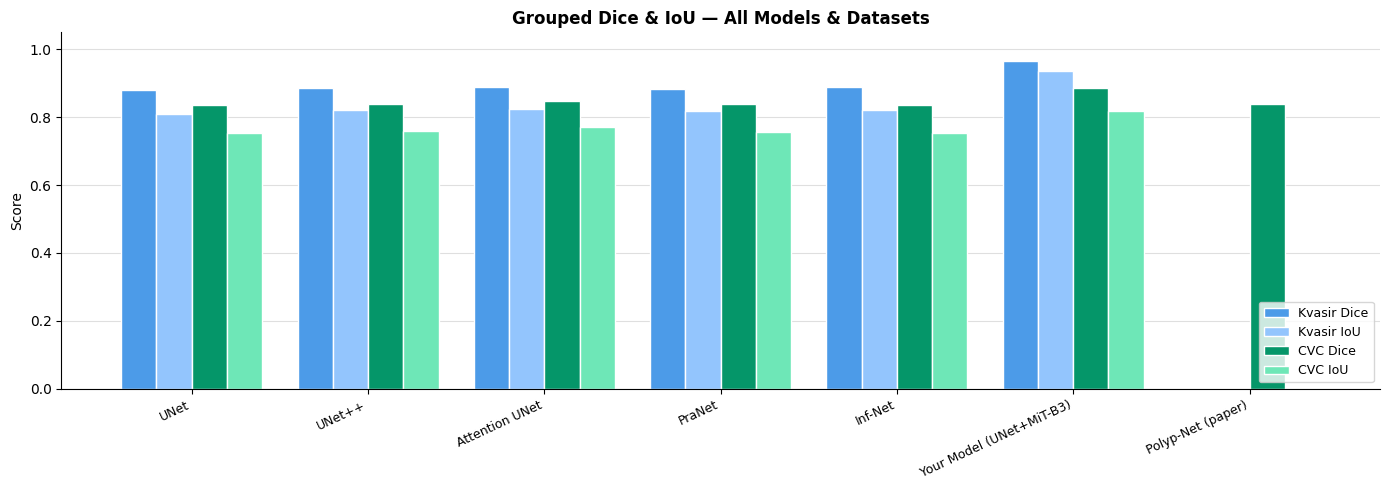

Grouped bar chart saved.


In [25]:
# ── Radar / spider chart for CVC-ClinicDB ────────────────────────────────────
from matplotlib.patches import FancyArrowPatch

# Collect models that have valid CVC dice AND IoU (skip nan-only)
radar_models  = []
radar_kv_d, radar_kv_i = [], []
radar_cvc_d, radar_cvc_i = [], []

for name, r in ALL_RESULTS.items():
    kd, ki = r['kvasir_dice'], r['kvasir_iou']
    cd, ci = r['cvc_dice'],    r['cvc_iou']
    if not (math.isnan(cd) and math.isnan(kd)):
        radar_models.append(name.replace('\n',' '))
        radar_kv_d.append(0. if math.isnan(kd) else kd)
        radar_kv_i.append(0. if math.isnan(ki) else ki)
        radar_cvc_d.append(0. if math.isnan(cd) else cd)
        radar_cvc_i.append(0. if math.isnan(ci) else ci)

x = np.arange(len(radar_models))
width = 0.20

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(x - 1.5*width, radar_kv_d,  width, label='Kvasir Dice',  color='#4C9BE8', edgecolor='white')
ax.bar(x - 0.5*width, radar_kv_i,  width, label='Kvasir IoU',   color='#93C5FD', edgecolor='white')
ax.bar(x + 0.5*width, radar_cvc_d, width, label='CVC Dice',     color='#059669', edgecolor='white')
ax.bar(x + 1.5*width, radar_cvc_i, width, label='CVC IoU',      color='#6EE7B7', edgecolor='white')

ax.set_xticks(x); ax.set_xticklabels(radar_models, rotation=25, ha='right', fontsize=9)
ax.set_ylim(0, 1.05); ax.set_ylabel('Score', fontsize=10)
ax.set_title('Grouped Dice & IoU — All Models & Datasets', fontsize=12, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
ax.yaxis.grid(True, alpha=0.4); ax.set_axisbelow(True)
ax.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig('grouped_comparison.png', dpi=130, bbox_inches='tight')
plt.show()
print('Grouped bar chart saved.')

5 checkpoints found for visualisation.


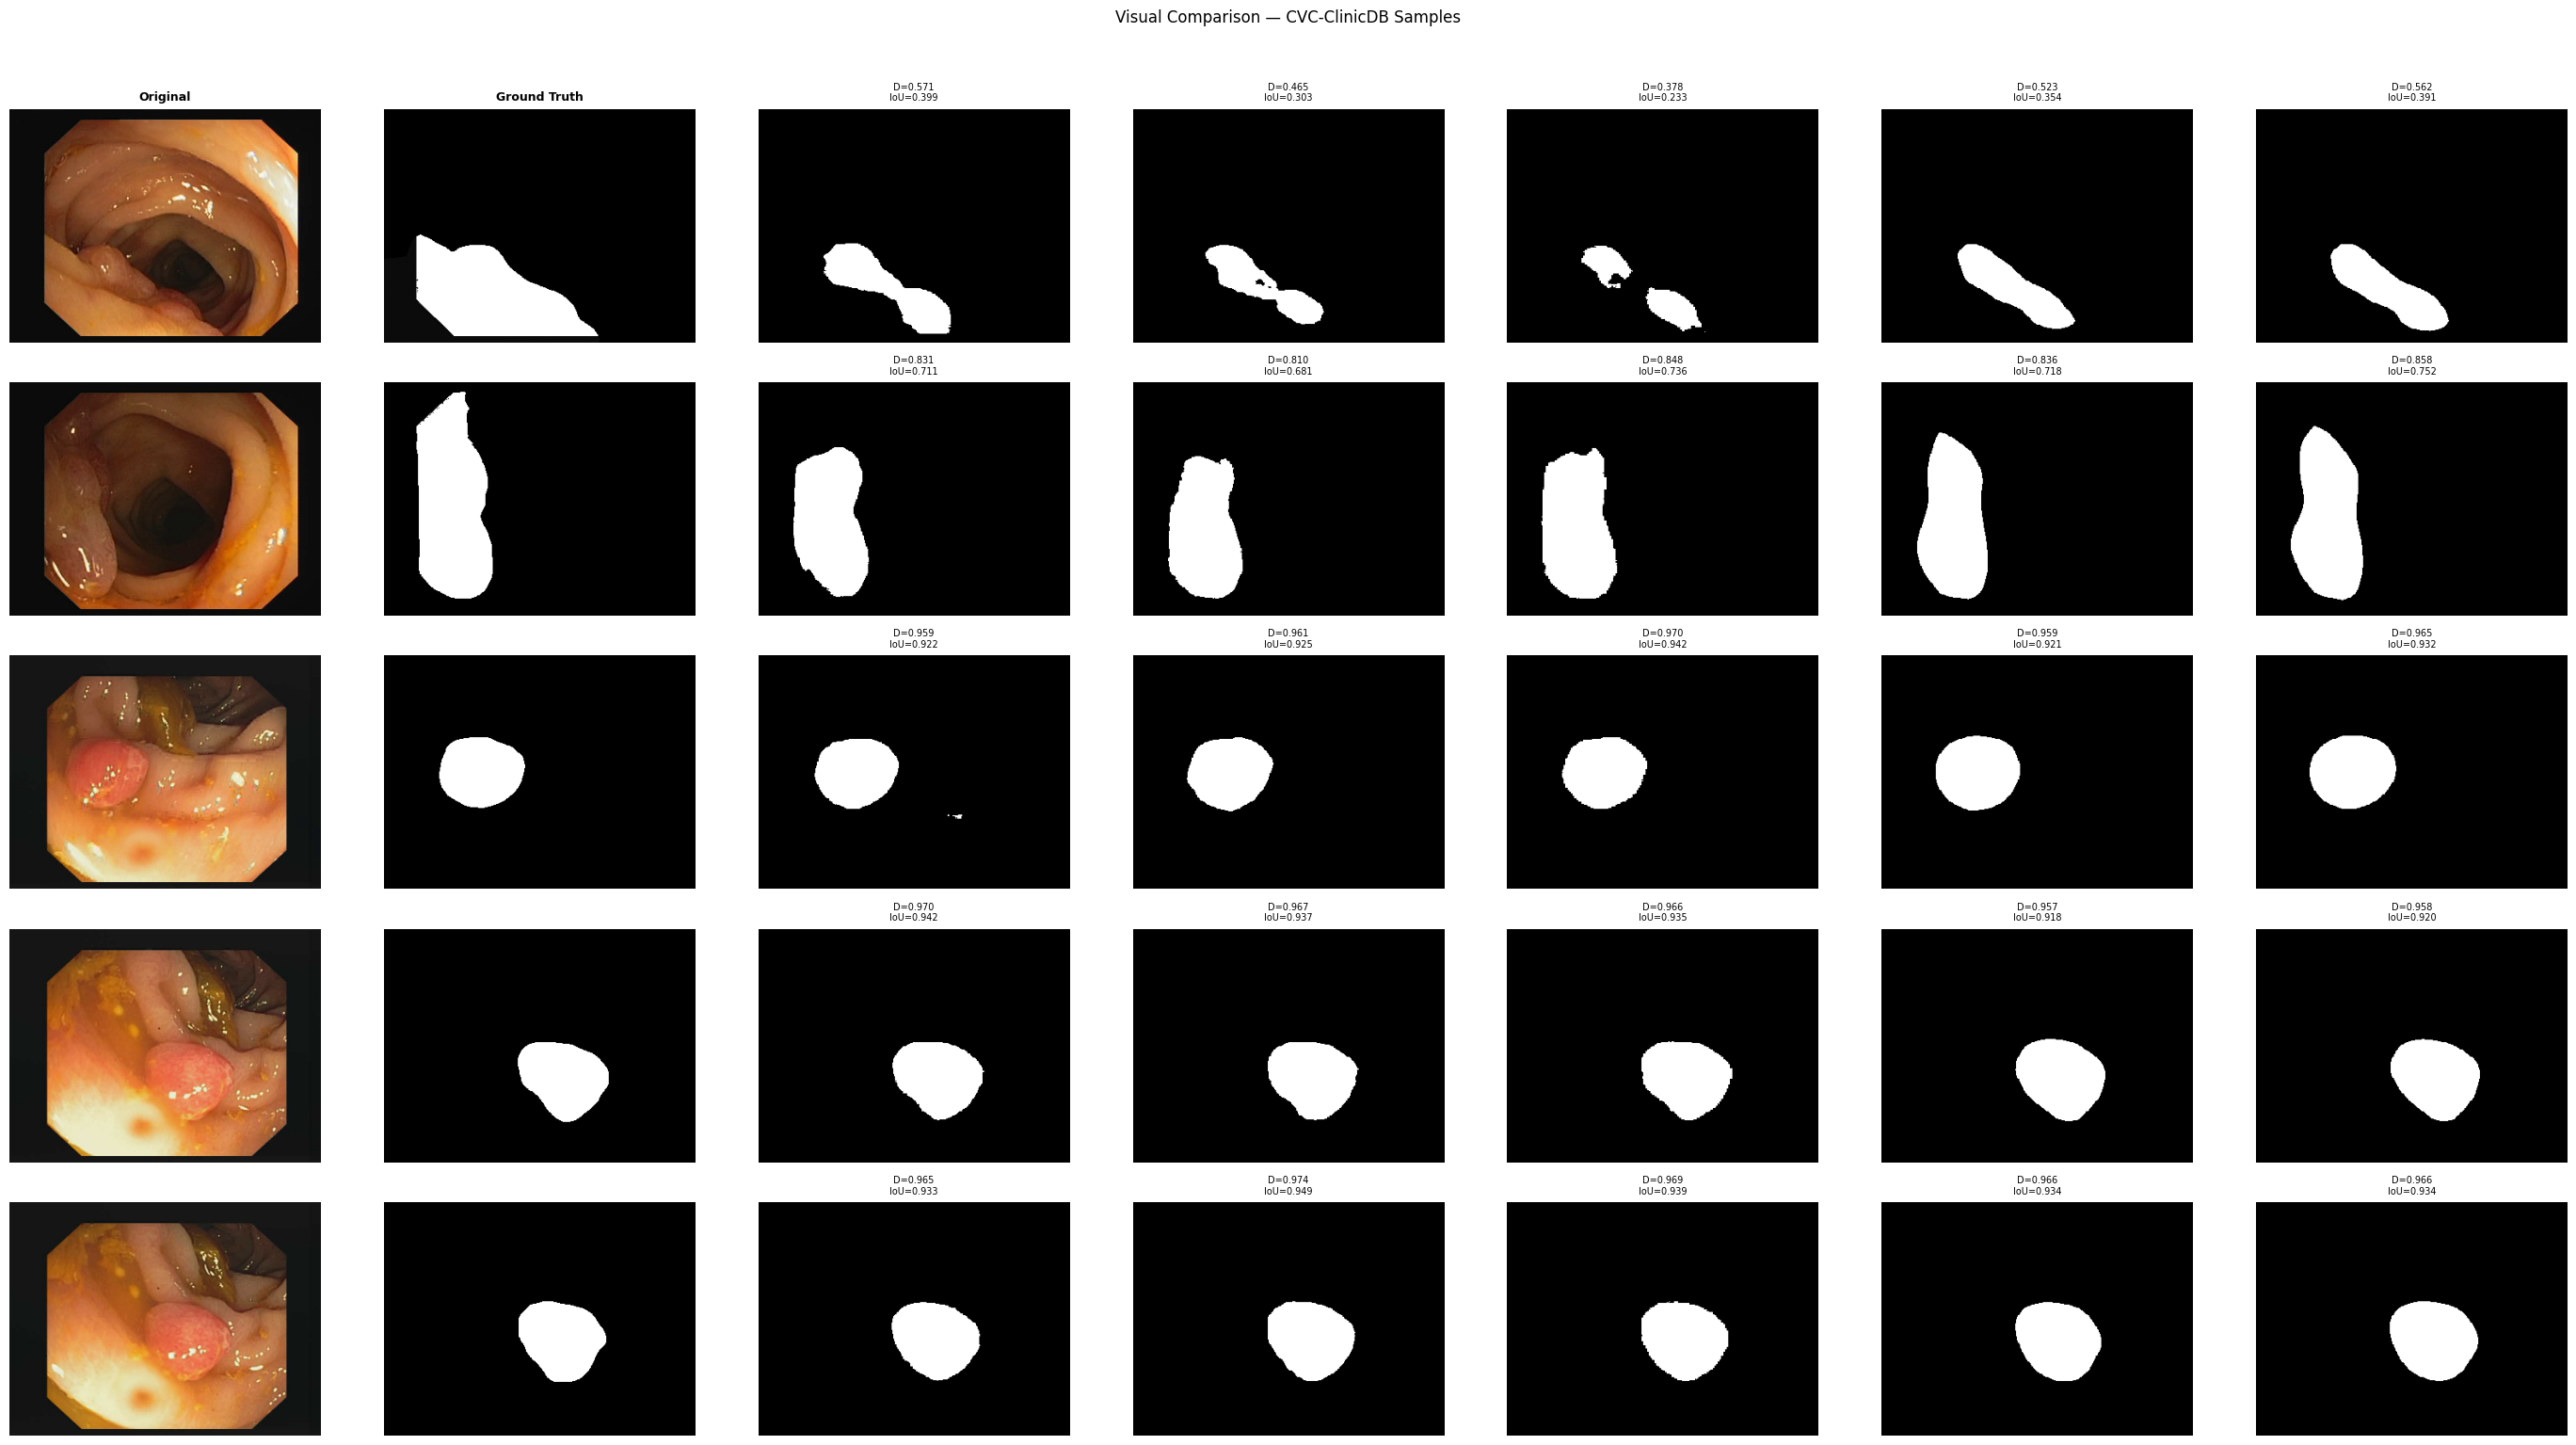

Visual comparison saved.


In [26]:
# ── Visual strip: show best/median/worst predictions for each model ──────────
# We reload each saved checkpoint and run on a few CVC-ClinicDB samples.

SAMPLE_N = 5   # images to show

val_tf = get_val_tf(IMG_SIZE)

def quick_preds(model_class_or_none, ckpt_path, img_paths, mask_paths,
                size=IMG_SIZE, multi_output=False):
    """Return list of (img_rgb, gt_mask, pred_mask, dice, iou) per image."""
    if model_class_or_none is None:
        return []
    ck = torch.load(ckpt_path, map_location='cpu')
    m  = model_class_or_none()
    state = ck.get('model_state_dict', ck)
    m.load_state_dict(state, strict=True)
    m.eval().to(DEVICE)

    results = []
    tf = get_val_tf(size)
    with torch.no_grad():
        for ip, mp in zip(img_paths, mask_paths):
            img_bgr = cv2.imread(str(ip))
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            gt      = cv2.imread(str(mp), cv2.IMREAD_GRAYSCALE)
            aug     = tf(image=img_rgb, mask=(gt/255.).astype(np.float32))
            img_t   = aug['image'].unsqueeze(0).float().to(DEVICE)
            with autocast():
                out = m(img_t)
                if isinstance(out,(list,tuple)): out=out[0]
            prob    = torch.sigmoid(out).squeeze().cpu().numpy()
            pred_b  = (prob > 0.5).astype(np.uint8)
            gt_b    = (gt   > 127).astype(np.uint8)
            pred_full = cv2.resize(pred_b, gt.shape[::-1], interpolation=cv2.INTER_NEAREST)
            d, u = calc_dice_iou(pred_full, gt_b)
            results.append((img_rgb, gt_b, pred_full, d, u))
    m.cpu(); del m
    return results

# pick SAMPLE_N images from CVC-ClinicDB
sample_imgs  = cvc_imgs[:SAMPLE_N]
sample_masks = cvc_masks[:SAMPLE_N]

# Map model name → (constructor, ckpt_path) — skip models without saved ckpt
ckpt_map = {
    'UNet'      : (lambda: smp.Unet('resnet34', encoder_weights=None, classes=1, activation=None),
                   CKPT_DIR/'UNet.pth'),
    'UNet++'    : (lambda: smp.UnetPlusPlus('resnet34', encoder_weights=None, classes=1, activation=None),
                   CKPT_DIR/'UNet++.pth'),
    'Att-UNet'  : (AttentionUNet,   CKPT_DIR/'Att-UNet.pth'),
    'PraNet'    : (PraNet,          CKPT_DIR/'PraNet.pth'),
    'Inf-Net'   : (InfNet,          CKPT_DIR/'Inf-Net.pth'),
}

n_models = sum(1 for _,p in ckpt_map.values() if Path(p).exists())
print(f'{n_models} checkpoints found for visualisation.')

if n_models > 0:
    fig, axes = plt.subplots(SAMPLE_N, 2 + n_models, figsize=(4*(2+n_models), SAMPLE_N*3))
    if SAMPLE_N == 1: axes = axes[np.newaxis,:]

    # Column headers
    headers = ['Original', 'Ground Truth']
    for nm, (_, p) in ckpt_map.items():
        if Path(p).exists(): headers.append(nm)
    for ax, h in zip(axes[0], headers):
        ax.set_title(h, fontsize=9, fontweight='bold')

    all_preds = {}
    for nm, (fn, p) in ckpt_map.items():
        if Path(p).exists():
            all_preds[nm] = quick_preds(fn, p, sample_imgs, sample_masks)

    for row in range(SAMPLE_N):
        img_bgr = cv2.imread(str(sample_imgs[row]))
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        gt      = cv2.imread(str(sample_masks[row]), cv2.IMREAD_GRAYSCALE)

        axes[row,0].imshow(img_rgb);          axes[row,0].axis('off')
        axes[row,1].imshow(gt, cmap='gray');  axes[row,1].axis('off')

        col = 2
        for nm in ckpt_map:
            if nm not in all_preds: continue
            pred = all_preds[nm][row][2]
            dice = all_preds[nm][row][3]
            iou  = all_preds[nm][row][4]
            axes[row, col].imshow(pred, cmap='gray')
            axes[row, col].set_title(f'D={dice:.3f}\nIoU={iou:.3f}', fontsize=7)
            axes[row, col].axis('off')
            col += 1

    plt.suptitle('Visual Comparison — CVC-ClinicDB Samples', fontsize=12, y=1.02)
    plt.tight_layout()
    plt.savefig('visual_comparison.png', dpi=100, bbox_inches='tight')
    plt.show()
    print('Visual comparison saved.')
else:
    print('No checkpoints to visualise.')

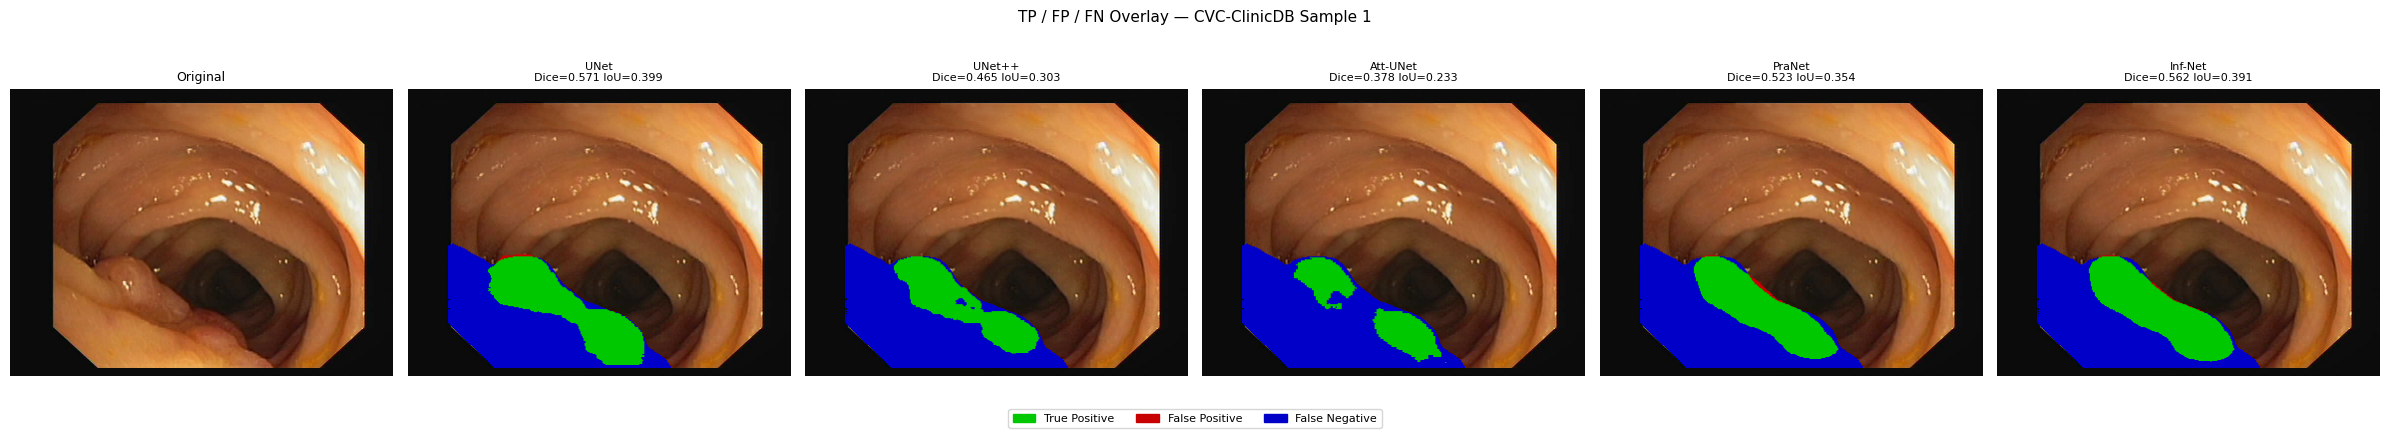

Overlay comparison saved.


In [27]:
# ── TP/FP/FN overlay for first CVC sample, across all available models ───────
if n_models > 0:
    row_data = [(nm, all_preds[nm][0]) for nm in ckpt_map if nm in all_preds]
    if row_data:
        img_bgr = cv2.imread(str(sample_imgs[0]))
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        gt_b    = (cv2.imread(str(sample_masks[0]),cv2.IMREAD_GRAYSCALE) > 127)

        fig, axes = plt.subplots(1, len(row_data)+1, figsize=(4*(len(row_data)+1), 4))
        axes[0].imshow(img_rgb); axes[0].set_title('Original', fontsize=9); axes[0].axis('off')

        for ax, (nm, (_, gt_, pred_, d, u)) in zip(axes[1:], row_data):
            H, W = img_rgb.shape[:2]
            pred_res = cv2.resize(pred_, (W,H), interpolation=cv2.INTER_NEAREST).astype(bool)
            gt_res   = cv2.resize(gt_.astype(np.uint8),(W,H),interpolation=cv2.INTER_NEAREST).astype(bool)
            overlay  = img_rgb.copy()
            overlay[ gt_res &  pred_res] = [0, 200,   0]   # TP — green
            overlay[~gt_res &  pred_res] = [200,  0,   0]  # FP — red
            overlay[ gt_res & ~pred_res] = [0,   0,  200]  # FN — blue
            ax.imshow(overlay)
            ax.set_title(f'{nm}\nDice={d:.3f} IoU={u:.3f}', fontsize=8)
            ax.axis('off')

        legend_els = [mpatches.Patch(color=[0,200/255,0],    label='True Positive'),
                      mpatches.Patch(color=[200/255,0,0],    label='False Positive'),
                      mpatches.Patch(color=[0,0,200/255],    label='False Negative')]
        fig.legend(handles=legend_els, loc='lower center', ncol=3,
                   fontsize=8, bbox_to_anchor=(0.5,-0.04))
        plt.suptitle('TP / FP / FN Overlay — CVC-ClinicDB Sample 1', fontsize=11, y=1.02)
        plt.tight_layout()
        plt.savefig('overlay_comparison.png', dpi=120, bbox_inches='tight')
        plt.show()
        print('Overlay comparison saved.')

In [28]:
# ── Final clean summary ──────────────────────────────────────────────────────
import math

print('\n' + '='*90)
print('                     POLYP SEGMENTATION — FINAL RESULTS SUMMARY')
print('='*90)
print(f"  {'Model':<30} | {'Kvasir Dice':>11} | {'Kvasir IoU':>10} | {'CVC Dice':>10} | {'CVC IoU':>10}")
print('  ' + '-'*86)

best_cvc_d = max((r['cvc_dice']   for r in ALL_RESULTS.values() if not math.isnan(r['cvc_dice'])), default=0)
best_kv_d  = max((r['kvasir_dice'] for r in ALL_RESULTS.values() if not math.isnan(r['kvasir_dice'])), default=0)

for name, r in ALL_RESULTS.items():
    label = name.replace('\n',' ')
    kd = r['kvasir_dice']; ki = r['kvasir_iou']
    cd = r['cvc_dice'];    ci = r['cvc_iou']

    kd_s = f'{kd:.4f}{"  ★" if abs(kd-best_kv_d)<1e-4 else "  "}' if not math.isnan(kd) else '   —     '
    ki_s = f'{ki:.4f}' if not math.isnan(ki) else '   —  '
    cd_s = f'{cd:.4f}{"  ★" if abs(cd-best_cvc_d)<1e-4 else "  "}' if not math.isnan(cd) else '   —     '
    ci_s = f'{ci:.4f}' if not math.isnan(ci) else '   —  '

    print(f"  {label:<30} | {kd_s:>11} | {ki_s:>10} | {cd_s:>10} | {ci_s:>10}")

print('='*90)
print()
print('  ★ = best in column')
print('  — = not evaluated')
print()
print('  Reference (literature, trained on Kvasir-SEG + CVC-ClinicDB combined):')
print('    PraNet  (Fan 2020)  CVC Dice ≈ 0.899,  IoU ≈ 0.849')
print('    HardNet (2021)      CVC Dice ≈ 0.912,  IoU ≈ 0.857')
print('    SANet   (2021)      CVC Dice ≈ 0.916,  IoU ≈ 0.859')
print()
print('  Note: models above were trained on both datasets combined — higher than')
print('  our single-dataset training is expected.')


                     POLYP SEGMENTATION — FINAL RESULTS SUMMARY
  Model                          | Kvasir Dice | Kvasir IoU |   CVC Dice |    CVC IoU
  --------------------------------------------------------------------------------------
  UNet                           |    0.8793   |     0.8086 |   0.8363   |     0.7548
  UNet++                         |    0.8865   |     0.8218 |   0.8390   |     0.7584
  Attention UNet                 |    0.8885   |     0.8249 |   0.8481   |     0.7715
  PraNet                         |    0.8833   |     0.8182 |   0.8374   |     0.7560
  Inf-Net                        |    0.8878   |     0.8210 |   0.8368   |     0.7527
  Your Model (UNet+MiT-B3)       |   0.9664  ★ |     0.9357 |  0.8848  ★ |     0.8180
  Polyp-Net (paper)              |      —      |        —   |   0.8390   |        —  

  ★ = best in column
  — = not evaluated

  Reference (literature, trained on Kvasir-SEG + CVC-ClinicDB combined):
    PraNet  (Fan 2020)  CVC Dice ≈ 0.899, 